# 02 — EEG Preprocessing

**Purpose:** Load raw EEG and apply band-pass, notch filter, and optional ICA.

In [1]:
import sys, os
PROJECT_ROOT = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, PROJECT_ROOT)
os.chdir(PROJECT_ROOT)
from src.config import load_config
from src.data_loader import EEGDataset
from src.preprocessing import EEGPreprocessor
config = load_config()
dataset = EEGDataset(config)
dataset.load_metadata()
preprocessor = EEGPreprocessor(config['preprocessing'])
print('Preprocessor ready')

Preprocessor ready


In [2]:
raw = dataset.load_eeg('sub-001')
print(f'Channels: {len(raw.ch_names)}, sfreq: {raw.info["sfreq"]} Hz')

Channels: 19, sfreq: 500.0 Hz


In [3]:
result = preprocessor.preprocess(raw)
print(f'Steps: {result.steps_applied}')
print(f'Duration: {result.duration_final:.1f}s')

Steps: ['bandpass_1.0_45.0Hz', 'notch_50.0Hz']
Duration: 599.8s


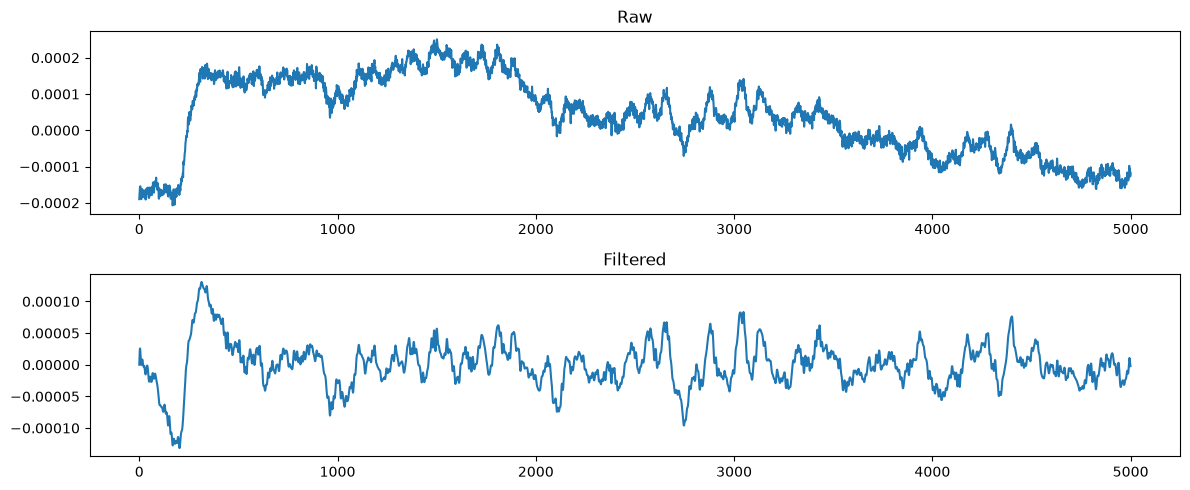

In [4]:
import matplotlib.pyplot as plt
raw_data = raw.get_data()[0][:5000]
filt_data = result.raw_filtered.get_data()[0][:5000]
fig, ax = plt.subplots(2,1,figsize=(12,5))
ax[0].plot(raw_data); ax[0].set_title('Raw')
ax[1].plot(filt_data); ax[1].set_title('Filtered')
plt.tight_layout(); plt.show()